## Codigo para pruebas de solo encoder para prediccion de elo

In [12]:
import os
import io
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm  # Usa tqdm normal si ejecutas desde script .py, o tqdm.notebook si usas Jupyter
import chess
import chess.pgn
import joblib

# Imports de PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# --- FIJAR SEMILLAS PARA REPRODUCIBILIDAD EN PYTORCH ---
SEED = 37

random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)  # Para cuando usas múltiples GPUs
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

plt.ion()

In [2]:
# Verificación de aceleración por GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo activo: {device}")
if device.type == "cuda":
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")

Dispositivo activo: cuda
GPU detectada: NVIDIA GeForce RTX 4060 Laptop GPU


In [3]:
# datos tomados del train
ELO_MIN = 1000 
ELO_MAX = 3390
ELO_MEAN = 2028.3
ELO_STD = 593.4
ELO_MEDIAN = 2028.0
ELO_Q1 = 1514.0
ELO_Q3 = 2538.0 
ELO_IQR = ELO_Q3 - ELO_Q1

In [4]:
def desnormalizar_elo(elo_norm, metodo):
    """Convierte el Elo normalizado de vuelta a puntos de Elo reales."""
    if metodo == "minmax":
        return elo_norm * (ELO_MAX - ELO_MIN) + ELO_MIN
    elif metodo == "standard":
        return elo_norm * ELO_STD + ELO_MEAN
    elif metodo == "robust":
        return elo_norm * ELO_IQR + ELO_MEDIAN
    else:
        return elo_norm

In [5]:
class PiecewiseLoss(nn.Module):
    def __init__(self,epsilon_elo, metodo, factor_suavizado=0.1):
        super().__init__()
        self.epsilon = epsilon_elo
        self.metodo = metodo
        self.factor = factor_suavizado

    def forward(self, predicciones, reales):

        if self.metodo == "minmax":
            epsilon_norm = self.epsilon / (ELO_MAX - ELO_MIN)
        elif self.metodo == "standard":
            epsilon_norm = self.epsilon / ELO_STD
        elif self.metodo == "robust":
            epsilon_norm = self.epsilon / ELO_IQR
        else:
            epsilon_norm = self.epsilon

        diferencia = torch.abs(predicciones - reales)
        error_base = diferencia ** 2

        mascara_adentro = (diferencia <= epsilon_norm).float()
        mascara_afuera = (diferencia > epsilon_norm).float()

        loss_adentro = error_base * mascara_adentro * self.factor
        loss_afuera = error_base * mascara_afuera

        return torch.mean(loss_adentro + loss_afuera)

In [6]:
class ChessDataset(Dataset):
    def __init__(self, npz_path, plies_a_usar=None, flatten=True, norm_type="standard", return_ids=False):
        datos = np.load(npz_path)

        X_completo = datos['X']
        plies_guardados = datos['plies_guardados'].tolist()
        self.return_ids = return_ids

        if plies_a_usar is None:
            indices = list(range(len(plies_guardados)))
        else:
            indices = [plies_guardados.index(p) for p in plies_a_usar]
            
        X_filtrado = X_completo[:, indices, :]
        
        if flatten:
            X_filtrado = X_filtrado.reshape(X_filtrado.shape[0], -1)
            
        # Homogeneizamos con el dataset de CNN: guardamos en RAM como int8
        self.X = torch.tensor(X_filtrado, dtype=torch.int8)

        self.game_idx = datos['game_idx']
        
        if norm_type == "minmax":
            y_seleccionada = datos['y_minmax']
        elif norm_type == "robust":
            y_seleccionada = datos['y_robust']
        elif norm_type == "raw":
            y_seleccionada = datos['y_raw']
        else:
            y_seleccionada = datos['y_standard'] # Por defecto
            
        # Lo pasamos a tensor y le damos forma (N, 1)
        self.y = torch.tensor(y_seleccionada, dtype=torch.float32).view(-1, 1)
        
        self.input_dim = self.X.shape[1] if flatten else self.X.shape[2]

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        # Casteo supereficiente a float32 solo para el lote actual
        x_tensor = self.X[idx].to(torch.float32)
        y_tensor = self.y[idx]
        
        if self.return_ids:
            idx_partida = self.game_idx[idx]
            return x_tensor, y_tensor, idx_partida
        else:
            return x_tensor, y_tensor

In [74]:
plies = [17] #

flatten = 1
crit = "huber" # "mse", "huber", "piece"
norm = "minmax" # "standard", "robust", "minmax"

test = "TEST" # VALIDATION O TEST

print("Cargando datasets a la memoria...")
ply_for_data = 51
train_ds = ChessDataset(f"../data/generado/only_enc/train_{ply_for_data}.npz", plies_a_usar=plies, flatten=flatten, norm_type=norm)
val_ds = ChessDataset(f"../data/generado/only_enc/val_{ply_for_data}.npz", plies_a_usar=plies, flatten=flatten, norm_type=norm,return_ids=True)
test_ds = ChessDataset(f"../data/generado/only_enc/test_{ply_for_data}.npz", plies_a_usar=plies, flatten=flatten, norm_type=norm, return_ids=True)

# El DataLoader se encarga de crear los batches y hacer el shuffle usando C++ internamente
train_loader = DataLoader(train_ds, batch_size=512, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=512, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=512, shuffle=False)
if test == "VALIDATION":
    loader = val_loader
else:
    loader = test_loader

Cargando datasets a la memoria...


In [ ]:
encoder_salida = f"../data/models/fully/prueba.pth"
#encoder_salida = f"../data/models/fully/{test}_{crit}_{norm}_{plies}.pth"
#pred_salida = f"../data/predict/prueba.npy"
pred_salida = f"../data/predict/fully_{test}_{crit}_{norm}_{plies}.npy"

In [59]:
#Encoder para una posición

class ChessEncoder(nn.Module):
    def __init__(self, input_dim):
        super(ChessEncoder, self).__init__()
        self.red = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(p=0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1) # Salida: 1 valor de Elo
        )

    def forward(self, x):
        return self.red(x)

In [60]:
"""class ChessEncoder(nn.Module): #early fusion
    def __init__(self, input_dim):
        super(ChessEncoder, self).__init__()
        
        # Arquitectura más compacta: previene el colapso de VRAM y mejora la generalización
        self.red = nn.Sequential(
            # Capa 1: Compresión inicial. Evitamos saltar a 4096 para controlar los pesos.
            nn.Linear(input_dim, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Dropout(p=0.4), # Dropout ligeramente mayor en la entrada para forzar robustez
            
            # Capa 2
            nn.Linear(2048, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            
            # Capa 3
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            
            # Capa 4 (Corregido de 258 a 256 por alineación de memoria en GPU)
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(p=0.2), # Reducimos el dropout a medida que se condensa la información
            
            # Capa 5: Transición final sin dropout
            nn.Linear(256, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            
            # Salida: 1 valor continuo (Elo)
            nn.Linear(64, 1) 
        )

    def forward(self, x):
        # x debe venir aplanado desde el DataLoader: (Batch, 832 * cant_plies)
        return self.red(x)"""

'class ChessEncoder(nn.Module): #early fusion\n    def __init__(self, input_dim):\n        super(ChessEncoder, self).__init__()\n\n        # Arquitectura más compacta: previene el colapso de VRAM y mejora la generalización\n        self.red = nn.Sequential(\n            # Capa 1: Compresión inicial. Evitamos saltar a 4096 para controlar los pesos.\n            nn.Linear(input_dim, 2048),\n            nn.BatchNorm1d(2048),\n            nn.ReLU(),\n            nn.Dropout(p=0.4), # Dropout ligeramente mayor en la entrada para forzar robustez\n\n            # Capa 2\n            nn.Linear(2048, 1024),\n            nn.BatchNorm1d(1024),\n            nn.ReLU(),\n            nn.Dropout(p=0.3),\n\n            # Capa 3\n            nn.Linear(1024, 512),\n            nn.BatchNorm1d(512),\n            nn.ReLU(),\n            nn.Dropout(p=0.3),\n\n            # Capa 4 (Corregido de 258 a 256 por alineación de memoria en GPU)\n            nn.Linear(512, 256),\n            nn.BatchNorm1d(256),\n    

In [61]:
"""# Encoder para multiples plies, comparten encoder al principio
class ChessEncoder(nn.Module):
    def __init__(self, input_dim, embed_dim=256):
        super(ChessEncoder, self).__init__()
        self.red = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            nn.Linear(512, embed_dim),
            nn.BatchNorm1d(embed_dim),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.red(x)  # (batch, embed_dim), ya NO es el Elo


class EloPredictor(nn.Module):
    def __init__(self, input_dim, embed_dim=256, n_plies=2):
        super(EloPredictor, self).__init__()
        self.encoder = ChessEncoder(input_dim, embed_dim)  # una sola instancia
        self.n_plies = n_plies
        self.head = nn.Sequential(
            nn.Linear(embed_dim * n_plies, 512), #
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(p=0.2),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, plies):
        # plies: lista de tensores (batch, input_dim), uno por cada ply
        embeddings = [self.encoder(plies[:, i, :]) for i in range(self.n_plies)]
        combined = torch.cat(embeddings, dim=1)
        return self.head(combined)"""

'# Encoder para multiples plies, comparten encoder al principio\nclass ChessEncoder(nn.Module):\n    def __init__(self, input_dim, embed_dim=256):\n        super(ChessEncoder, self).__init__()\n        self.red = nn.Sequential(\n            nn.Linear(input_dim, 512),\n            nn.BatchNorm1d(512),\n            nn.ReLU(),\n            nn.Dropout(p=0.3),\n\n            nn.Linear(512, embed_dim),\n            nn.BatchNorm1d(embed_dim),\n            nn.ReLU(),\n        )\n\n    def forward(self, x):\n        return self.red(x)  # (batch, embed_dim), ya NO es el Elo\n\n\nclass EloPredictor(nn.Module):\n    def __init__(self, input_dim, embed_dim=256, n_plies=2):\n        super(EloPredictor, self).__init__()\n        self.encoder = ChessEncoder(input_dim, embed_dim)  # una sola instancia\n        self.n_plies = n_plies\n        self.head = nn.Sequential(\n            nn.Linear(embed_dim * n_plies, 512), #\n            nn.BatchNorm1d(512),\n            nn.ReLU(),\n            nn.Dropout(p=

In [62]:
if flatten:
    modelo = ChessEncoder(input_dim=train_ds.X.shape[1]).to(device)
else: 
    modelo = EloPredictor(input_dim=train_ds.X.shape[2],n_plies=len(plies)).to(device)

if len(plies)>1:
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-4, weight_decay=1e-4)
else:
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-3, weight_decay=1e-4)
    
if crit == "huber":
    if norm == "minmax":
        criterio = nn.HuberLoss(delta=0.1)
    elif norm == "robust":
        criterio = nn.HuberLoss(delta=0.3)
    else:
        criterio = nn.HuberLoss(delta=1)
elif crit == "mse":
    criterio = nn.MSELoss()  # eleva los errores al cuadrado, lo que hace que tienda a predecir la media
elif crit == "piece":
    criterio = PiecewiseLoss(epsilon_elo=200.0,metodo=norm,factor_suavizado=0.1)

In [63]:
# --- BUCLE DE ENTRENAMIENTO ---
epocas = 50
paciencia = 5
mejor_val_loss = float('inf')
epocas_sin_mejora = 0


for epoca in range(epocas):
    # Fase de Entrenamiento
    modelo.train()
    train_loss = 0.0
    
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        
        optimizador.zero_grad()           # 1. Limpiar gradientes viejos
        predicciones = modelo(batch_X)    # 2. Predecir
        loss = criterio(predicciones, batch_y) # 3. Calcular el error
        loss.backward()                   # 4. Propagar el error hacia atrás (Backprop)
        optimizador.step()                # 5. Actualizar los pesos
        
        train_loss += loss.item() * batch_X.size(0)
    
    # Fase de Validación
    modelo.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch_X, batch_y,_ in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            predicciones = modelo(batch_X)
            loss = criterio(predicciones, batch_y)
            val_loss += loss.item() * batch_X.size(0)
            
    # Promedios de la época
    train_loss /= len(train_loader.dataset)
    val_loss /= len(val_loader.dataset)
    print(f"Época {epoca+1}/{epocas} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
    
    # --- EARLY STOPPING ---
    if val_loss < mejor_val_loss:
        mejor_val_loss = val_loss
        epocas_sin_mejora = 0
        
        # 1. Empaquetamos los pesos y los metadatos del experimento
        checkpoint = {
            'input_dim': train_ds.input_dim,
            'arquitectura': 'Dense_512_256_128_32',
            'epoca_optima': epoca + 1,
            'estado_pesos': modelo.state_dict()
        }
        
        # 2. Guardo el archivo
        torch.save(checkpoint, encoder_salida) 
        
    else:
        epocas_sin_mejora += 1
        if epocas_sin_mejora >= paciencia:
            print(f"\nEarly stopping activado. El modelo no mejoró en {paciencia} épocas.")
            print(f"Recuperando los mejores pesos de la época {epoca + 1 - paciencia}...")
            
            # 3. Cargamos el archivo completo a la RAM
            checkpoint_recuperado = torch.load(encoder_salida)
            
            modelo.load_state_dict(checkpoint_recuperado['estado_pesos'])

            break

Época 1/50 | Train Loss: 0.0132 | Val Loss: 0.0109
Época 2/50 | Train Loss: 0.0120 | Val Loss: 0.0107
Época 3/50 | Train Loss: 0.0116 | Val Loss: 0.0103
Época 4/50 | Train Loss: 0.0114 | Val Loss: 0.0104
Época 5/50 | Train Loss: 0.0113 | Val Loss: 0.0103
Época 6/50 | Train Loss: 0.0111 | Val Loss: 0.0102
Época 7/50 | Train Loss: 0.0110 | Val Loss: 0.0102
Época 8/50 | Train Loss: 0.0109 | Val Loss: 0.0101
Época 9/50 | Train Loss: 0.0108 | Val Loss: 0.0101
Época 10/50 | Train Loss: 0.0107 | Val Loss: 0.0101
Época 11/50 | Train Loss: 0.0107 | Val Loss: 0.0101
Época 12/50 | Train Loss: 0.0106 | Val Loss: 0.0102
Época 13/50 | Train Loss: 0.0105 | Val Loss: 0.0101
Época 14/50 | Train Loss: 0.0105 | Val Loss: 0.0100
Época 15/50 | Train Loss: 0.0104 | Val Loss: 0.0101
Época 16/50 | Train Loss: 0.0104 | Val Loss: 0.0100
Época 17/50 | Train Loss: 0.0103 | Val Loss: 0.0101
Época 18/50 | Train Loss: 0.0103 | Val Loss: 0.0101
Época 19/50 | Train Loss: 0.0102 | Val Loss: 0.0100
Época 20/50 | Train L

C:\Users\agust\AppData\Local\Temp\ipykernel_22488\3216849270.py:62: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint_recuperado = torch.load(encoder_salida)


In [64]:
# Evaluación en la validation o en test
modelo.eval() 
y_true_list = []
y_pred_list = []
lista_indices_pgn = []
print(f"Calculando predicciones en el {test} set...")
with torch.no_grad():
    for batch_X, batch_y, batch_idx in loader:
        batch_X = batch_X.to(device)
        
        # Predecir
        predicciones = modelo(batch_X)
        
        # Mover a la CPU, convertir a numpy y guardar en la lista
        y_pred_list.extend(predicciones.cpu().numpy().flatten())
        y_true_list.extend(batch_y.numpy().flatten())
        lista_indices_pgn.extend(batch_idx.numpy())

# --- 4. DESNORMALIZAR ---
y_true_real = desnormalizar_elo(np.array(y_true_list), norm)
y_pred_real = desnormalizar_elo(np.array(y_pred_list), norm)
np.save(pred_salida, y_pred_real)


Calculando predicciones en el TEST set...


In [76]:
# Tomar predicciones de uno de los archivos

y_true_list = []
y_pred_list = []

with torch.no_grad():
    for batch_X, batch_y, batch_idx in loader:
        batch_X = batch_X.to(device)
        y_true_list.extend(batch_y.numpy().flatten())

y_true_real = desnormalizar_elo(np.array(y_true_list), norm)
ruta_archivo = "../data/predict/fully_TEST_mse_standard_[15, 23, 31, 39, 47].npy" 
y_pred_real = np.load(ruta_archivo)

In [77]:
errores_absolutos = np.abs(y_true_real - y_pred_real)
errores_cuadraticos = (y_true_real - y_pred_real) ** 2

# 2. Calculamos las métricas globales
mae = np.mean(errores_absolutos)
mse = np.mean(errores_cuadraticos)
rmse = np.sqrt(mse)

# 3. Métricas extra útiles para la tesis
error_mediano = np.median(errores_absolutos)
max_error = np.max(errores_absolutos)
print(test)
print(f"Criterio: {crit}      Normalizacion {norm}     Ply: {plies}")
print(f"MAE (Error Absoluto Medio):   {mae:.1f} puntos de Elo")
print(f"Mediana del Error:            {error_mediano:.1f} puntos de Elo")
print(f"RMSE (Raíz Error Cuadrático): {rmse:.1f} puntos de Elo")
print(f"Peor equivocación del modelo: {max_error:.1f} puntos de Elo")

TEST
Criterio: huber      Normalizacion minmax     Ply: [17]
MAE (Error Absoluto Medio):   311.7 puntos de Elo
Mediana del Error:            249.6 puntos de Elo
RMSE (Raíz Error Cuadrático): 402.3 puntos de Elo
Peor equivocación del modelo: 1671.2 puntos de Elo


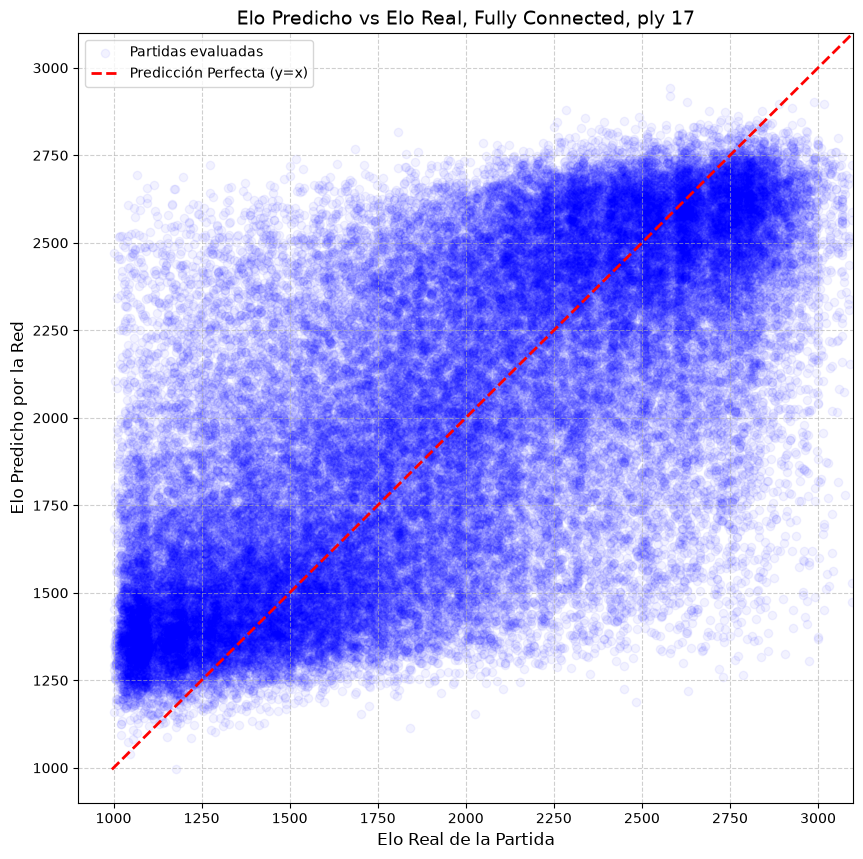

In [78]:
plt.figure(figsize=(10, 10))

plt.scatter(y_true_real, y_pred_real, alpha=0.05, color='blue', label='Partidas evaluadas')

min_val = min(min(y_true_real), min(y_pred_real))
max_val = max(max(y_true_real), max(y_pred_real))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Predicción Perfecta (y=x)')

plt.title(f'Elo Predicho vs Elo Real, Fully Connected, ply 17', fontsize=14)
plt.xlabel('Elo Real de la Partida', fontsize=12)
plt.ylabel('Elo Predicho por la Red', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Limitar los ejes a valores lógicos del ajedrez (ej. 800 a 3000)
plt.xlim(900, 3100)
plt.ylim(900, 3100)
plt.show()

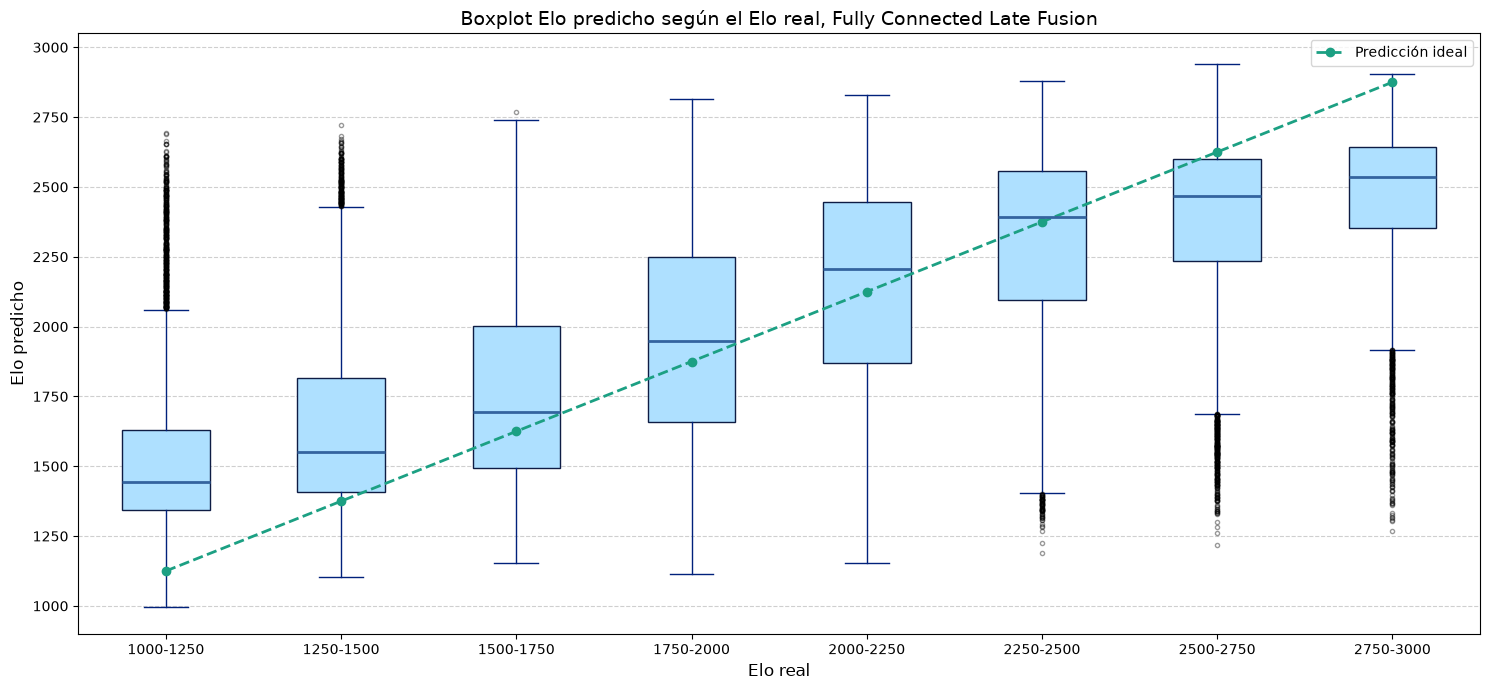

In [91]:
bins = np.arange(1000, 3001, 250)
etiquetas_tramos = [
    f"{bins[i]}-{bins[i+1]}" 
    for i in range(len(bins)-1)
]

predicciones_por_tramo = []
medias_ideales = []
etiquetas_validas = []

for i in range(len(bins)-1):
    limite_inferior = bins[i]
    limite_superior = bins[i+1]

    mascara = (
        (y_true_real >= limite_inferior) &
        (y_true_real < limite_superior)
    )

    predicciones_filtradas = y_pred_real[mascara]

    if len(predicciones_filtradas) == 0:
        continue

    predicciones_por_tramo.append(predicciones_filtradas)
    medias_ideales.append(
        (limite_inferior + limite_superior) / 2
    )
    etiquetas_validas.append(etiquetas_tramos[i])


plt.figure(figsize=(15, 7))

plt.boxplot(
    predicciones_por_tramo,
    tick_labels=etiquetas_validas,
    patch_artist=True,
    boxprops=dict(facecolor="#AEE0FF", color="#0E1C44"),
    medianprops=dict(color="#34649F", linewidth=2),
    whiskerprops=dict(color="#01217B"),
    capprops=dict(color="#01217B"),
    flierprops=dict(marker='o', markersize=3, alpha=0.4)
)

x_pos = np.arange(1, len(etiquetas_validas) + 1)

plt.plot(
    x_pos,
    medias_ideales,
    color="#1CA083",
    linestyle='--',
    linewidth=2,
    marker='o',
    label='Predicción ideal'
)

plt.title(
    'Boxplot Elo predicho según el Elo real, Fully Connected Late Fusion',
    fontsize=14
)

plt.xlabel('Elo real', fontsize=12)
plt.ylabel('Elo predicho', fontsize=12)
plt.ylim(900, 3050)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()

plt.show()

### Código para printear los 10 tableros con mayor diferencia entre elo predicho y real 

In [199]:
# Función para decodificar tu tensor (13x8x8) a un tablero de python-chess
def decodificar_tensor_a_tablero(tensor_plano):

    matriz = tensor_plano.reshape(13, 8, 8)
    tablero = chess.Board(None) # Tablero vacío
    
    # IMPORTANTE: Este orden debe coincidir EXACTAMENTE con cómo armaste tu dataset.
    # Usualmente es: peón, caballo, alfil, torre, reina, rey (blancas y luego negras)
    piezas_str = "PNBRQKpnbrqk" 
    piezas_str = "PpRrNnBbQqKk"
    for canal, letra_pieza in enumerate(piezas_str):
        capa = matriz[canal]
        # Buscamos dónde hay un '1'
        for fila in range(8):
            for col in range(8):
                if capa[fila, col] == 1:
                    # Mapeo de coordenadas de matriz (0-7) a casillas de ajedrez (0-63)
                    # Asumiendo que fila 0 de tu matriz es la fila 8 (A8-H8) del ajedrez
                    square = (7 - fila) * 8 + col 
                    pieza = chess.Piece.from_symbol(letra_pieza)
                    tablero.set_piece_at(square, pieza)
                    
    return tablero



In [200]:
top_10_indices = np.argsort(errores_absolutos)[-10:][::-1]

print("=== TOP 10 PEORES PREDICCIONES ===")

for rank, idx in enumerate(top_10_indices):
    elo_real = y_true_real[idx]
    elo_pred = y_pred_real[idx]
    error_abs = errores_absolutos[idx]
    
    print(f"\n--- Puesto #{rank + 1} ---")
    print(f"Índice en dataset: {idx}")
    print(f"Elo Real: {elo_real:.0f} | Elo Predicho: {elo_pred:.0f} | Error: {error_abs:.0f} puntos")
    
    # Extraemos el tensor original directamente de tu dataset de test
    # test_dataset[idx] devuelve una tupla (X, y). Tomamos X.
    tensor_x = test_ds[idx][0][1].numpy()
    print(tensor_x.shape)
    tablero = decodificar_tensor_a_tablero(tensor_x)
    
    # Si estás en Jupyter Notebook, display(tablero) muestra la imagen directamente
    display(tablero)

=== TOP 10 PEORES PREDICCIONES ===

--- Puesto #1 ---
Índice en dataset: 12087
Elo Real: 3018 | Elo Predicho: 1361 | Error: 1656 puntos
()


ValueError: cannot reshape array of size 1 into shape (13,8,8)

### Código para graficar losses del encoder según ply (individual)

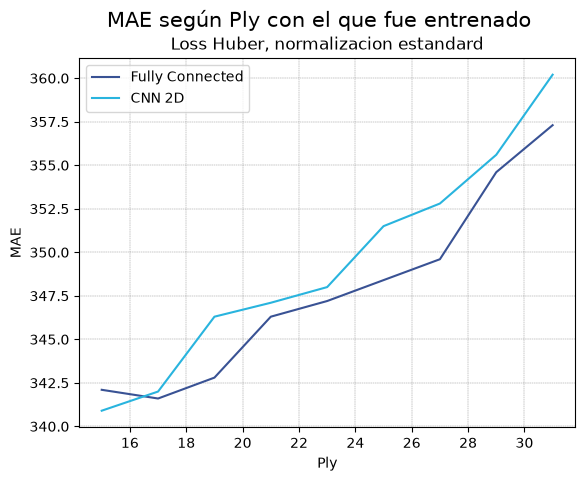

In [79]:
loss_encoder = [342.1, 341.6, 342.8, 346.3, 347.2, 348.4, 349.6, 354.6, 357.3]
loss_convolutional = [340.9, 342.0, 346.3, 347.1, 348.0, 351.5, 352.8, 355.6, 360.2]

ply = np.arange(15,32,2)
plt.plot(ply,loss_encoder, label= "Fully Connected",color="#395294")
plt.plot(ply,loss_convolutional, label= "CNN 2D",color="#29b4de")
plt.suptitle("MAE según Ply con el que fue entrenado",fontsize=15)
plt.title("Loss Huber, normalizacion estandard")
plt.xlabel("Ply")
plt.ylabel("MAE")
plt.grid(color='gray', linestyle='--', linewidth=0.3)
plt.legend()

### Gráfico de todas las losses

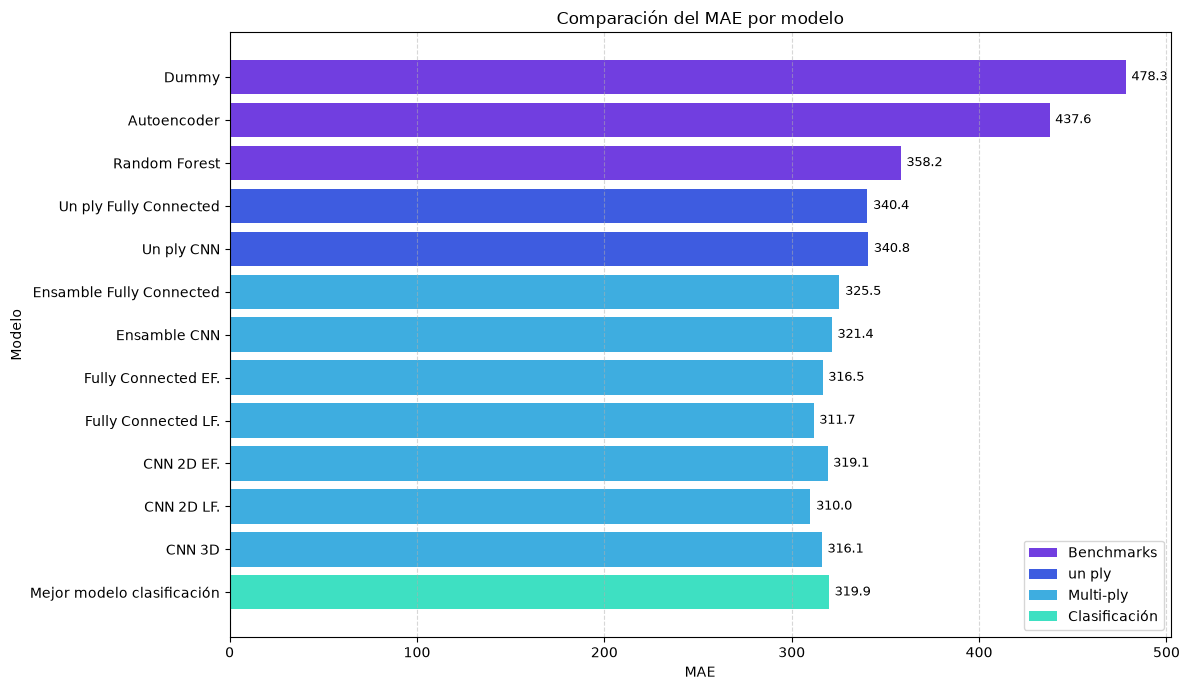

In [ ]:
from matplotlib.patches import Patch
mae = [478.3,437.6,358.2,340.4,340.8,325.5,321.4,316.5,311.7,319.1,310.0,316.1,319.9]
modelo = ["Dummy","Autoencoder","Random Forest","Un ply Fully Connected","Un ply CNN","Ensamble Fully Connected", "Ensamble CNN","Fully Connected EF.","Fully Connected LF.", "CNN 2D EF.", "CNN 2D LF.", "CNN 3D","Mejor modelo clasificación"]
colores = (
    ["#713EE0"] * 3 +       
    ["#3E5CE0"] * 2 +     
    ["#3EADE0"] * 7 +       
    ["#3EE0C2"] * 3        
)

plt.figure(figsize=(12, 7))

bars = plt.barh(modelo, mae, color=colores)

# Mostrar el valor al final de cada barra
for bar in bars:
    valor = bar.get_width()
    plt.text(
        valor + 3,  # Separación respecto al final de la barra
        bar.get_y() + bar.get_height() / 2,
        f'{valor:.1f}',
        va='center',
        ha='left',
        fontsize=9
    )

plt.xlabel("MAE")
plt.ylabel("Modelo")
plt.title("Comparación del MAE por modelo")

plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.gca().invert_yaxis()

leyenda = [
    Patch(facecolor="#713EE0", label='Benchmarks'),
    Patch(facecolor="#3E5CE0", label='Un ply'),
    Patch(facecolor="#3EADE0", label='Multiples plies'),
    Patch(facecolor="#3EE0C2", label='Clasificación')
]

plt.legend(handles=leyenda, loc='lower right')
plt.tight_layout()
plt.show()